### IMPORT AND READ DATASET

In [141]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

In [142]:
# Read the dataset
data = pd.read_csv('messy_housing_data.csv')

data.head()
data.info()
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   area_sqft   420 non-null    int64  
 1   bedrooms    399 non-null    float64
 2   bathrooms   420 non-null    int64  
 3   year_built  384 non-null    float64
 4   price       370 non-null    object 
 5   location    420 non-null    object 
dtypes: float64(2), int64(2), object(2)
memory usage: 19.8+ KB


,area_sqft,bedrooms,bathrooms,year_built
count,420.000000,399.000000,420.00000,384.000000
mean,2621.888095,3.593985,3.02381,1960.197917
std,1330.825892,2.386218,1.45067,37.715887
min,-100.000000,1.000000,1.00000,1900.000000
25%,1462.500000,2.000000,2.00000,1926.000000
50%,2602.000000,3.000000,3.00000,1959.000000
75%,3709.000000,5.000000,4.00000,1994.000000
max,4999.000000,20.000000,5.00000,2026.000000


## DATA CLEANING

In [143]:
# Check for missing values
print(f"Missing values per column:\n{data.isnull().sum()}")

#Check data types
print(f"\nData types before conversion:\n{data.dtypes}")

Missing values per column:
area_sqft      0
bedrooms      21
bathrooms      0
year_built    36
price         50
location       0
dtype: int64

Data types before conversion:
area_sqft       int64
bedrooms      float64
bathrooms       int64
year_built    float64
price          object
location       object
dtype: object


In [144]:
# Clean 'price' column 
data['price'] = data['price'].astype(str).str.strip()

# Remove unwanted characters and convert to numeric
data['price'] = data['price'].replace(
    {r'\$': '', ',': '', r'(?i)^unavailable$': '', r'(?i)^n/?a$': ''},
    regex=True,
)

# Convert 'price' column to numeric, coercing errors to NaN
data['price'] = pd.to_numeric(data['price'], errors='coerce')

In [145]:
numeric_cols = [
    'area_sqft',
    'bedrooms',
    'bathrooms',
    'year_built'
]
# Convert other numeric columns to numeric type, coercing errors to NaN
for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors='coerce')

print("\nData types after conversion:")
print(data.dtypes)


Data types after conversion:
area_sqft       int64
bedrooms      float64
bathrooms       int64
year_built    float64
price         float64
location       object
dtype: object


In [146]:
# Remove outliers and invalid values
data.loc[(data['area_sqft'] <= 0) | (data['area_sqft'] > 10000), 'area_sqft'] = np.nan
data.loc[(data['bedrooms'] <= 0) | (data['bedrooms'] > 10), 'bedrooms'] = np.nan
data.loc[(data['bathrooms'] <= 0) | (data['bathrooms'] > 10), 'bathrooms'] = np.nan
data.loc[(data['year_built'] < 1800) | (data['year_built'] > 2025), 'year_built'] = np.nan
data.loc[(data['price'] < 100000) | (data['price'] > 10000000), 'price'] = np.nan

In [147]:
# Location mapping for standardization
LOCATION_MAP = {
    'sf': 'san francisco', 's.f.': 'san francisco', 'san francisco': 'san francisco',
    'la': 'los angeles', 'l.a.': 'los angeles', 'los angeles': 'los angeles',
    'nyc': 'new york', 'new york city': 'new york', 'new york': 'new york',
    'austin': 'austin',
    'chicago': 'chicago', 'chicgo': 'chicago',
    'boston': 'boston', 'bostan': 'boston',
    'miami': 'miami',
}

# Function to normalize location names
def normalize_location(x):
    x = str(x).strip().lower()
    return LOCATION_MAP.get(x, x)

# Apply normalization to the 'location' column
data['location'] = data['location'].map(normalize_location)

print(f"\nUnique locations after normalization:\n{data['location'].unique()}")



Unique locations after normalization:
['austin' 'san francisco' 'chicago' 'new york' 'miami' 'los angeles'
 'boston']


In [148]:
rows_before = len(data)

# Drop rows with missing or invalid price values
data = data.dropna(subset=['price']).reset_index(drop=True)

rows_after = len(data)

print(
    f"\nRemoved {rows_before - rows_after} rows "
    f"with missing/invalid price values."
)



Removed 65 rows with missing/invalid price values.


In [149]:
# Fill missing values in feature columns with median values
feature_cols = ['area_sqft', 'bedrooms', 'bathrooms', 'year_built']
data[feature_cols] = data[feature_cols].fillna(data[feature_cols].median())

# Convert 'bedrooms', 'year_built' and 'bathrooms' to integer types
data['bedrooms'] = data['bedrooms'].astype('int64')
data['year_built'] = data['year_built'].astype('int64')
data['bathrooms'] = data['bathrooms'].astype('int64')

print("\nData types after final conversion:")
print(data.dtypes)

print("\nRemaining missing values:")
print(data.isnull().sum())


Data types after final conversion:
area_sqft     float64
bedrooms        int64
bathrooms       int64
year_built      int64
price         float64
location       object
dtype: object

Remaining missing values:
area_sqft     0
bedrooms      0
bathrooms     0
year_built    0
price         0
location      0
dtype: int64


In [150]:
# Create a binary classification target variable based on the median price
threshold = data['price'].median()
data['price_category'] = np.where(data['price'] >= threshold, 'high', 'low')

print(f"Class distribution:\n{data['price_category'].value_counts()}")
print(f"\nPercentages:\n{data['price_category'].value_counts(normalize=True).round(3)}")

# Display the first few rows of the 'price' and 'price_category' columns
data[['price', 'price_category']].head()

Class distribution:
price_category
high    178
low     177
Name: count, dtype: int64

Percentages:
price_category
high    0.501
low     0.499
Name: proportion, dtype: float64


,price,price_category
0,2068779.98,high
1,1539208.46,high
2,557909.70,low
3,716945.96,low
4,574438.17,low


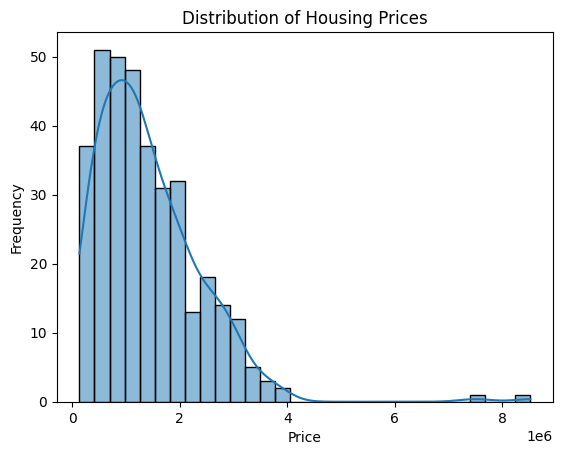

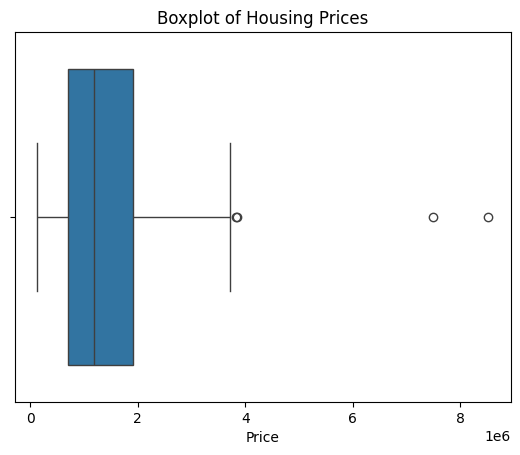

In [151]:
# Distribution of Housing Prices
sns.histplot(data['price'], bins=30, kde=True)
plt.title('Distribution of Housing Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

# Boxplot of Housing Prices
sns.boxplot(x=data['price'])
plt.title('Boxplot of Housing Prices')
plt.xlabel('Price')
plt.show()

In [152]:
# Display the distribution of the 'location' column
data['location'].value_counts()

location
san francisco    70
los angeles      68
new york         65
chicago          43
austin           42
boston           40
miami            27
Name: count, dtype: int64

In [153]:
# Define independent variables
X = data[['area_sqft', 'bedrooms', 'bathrooms', 'year_built', 'location']]
# Define dependent variable
Y = data['price_category']

# Convert categorical variable 'location' into dummy variables
X = pd.get_dummies(X, columns=['location'], drop_first=True)
X.head()

# Split the dataset into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

## EXPLORATORY DATA ANALYSIS

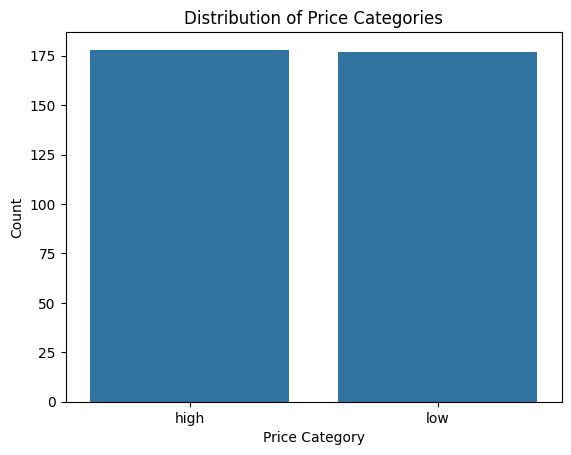

In [154]:
# Visualize the distribution of price categories
sns.countplot(x=Y)
plt.title('Distribution of Price Categories')
plt.xlabel('Price Category')
plt.ylabel('Count')
plt.show()

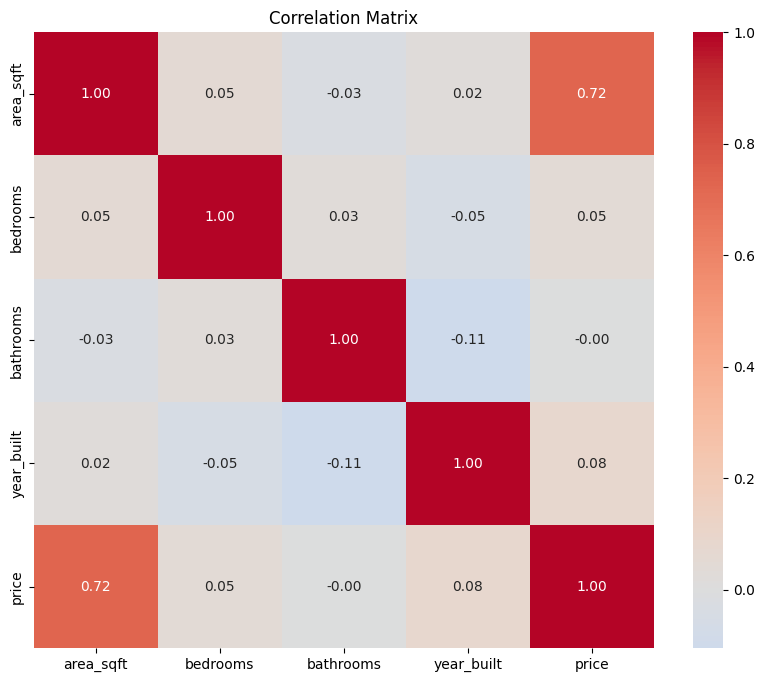

In [155]:
# Correlation matrix for numerical features
numeric_features = ['area_sqft', 'bedrooms', 'bathrooms', 'year_built']
plt.figure(figsize=(10, 8))
correlation_matrix = data[numeric_features + ['price']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

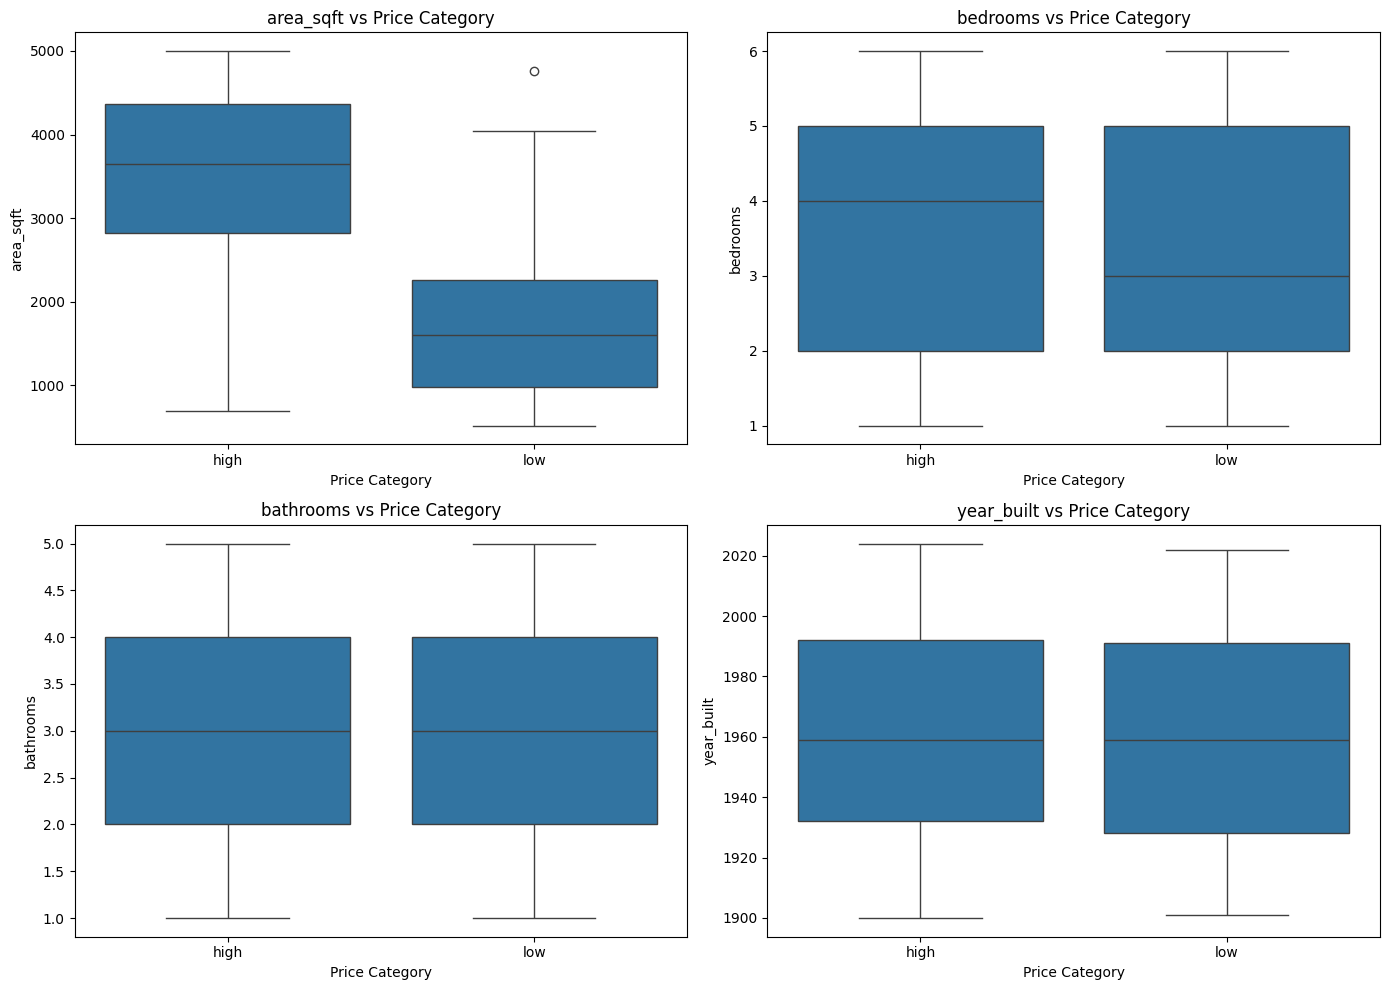

In [156]:
# Relationship between features and target
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

# Plot boxplots for numerical features against price category
for idx, col in enumerate(numeric_features):
    sns.boxplot(data=data, x='price_category', y=col, ax=axes[idx])
    axes[idx].set_title(f'{col} vs Price Category')
    axes[idx].set_xlabel('Price Category')
    axes[idx].set_ylabel(col)

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

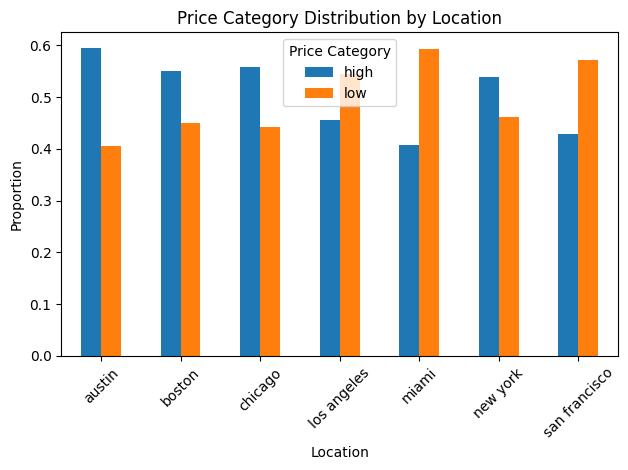

In [157]:
# Distribution by location
plt.figure(figsize=(12, 6))
location_price = data.groupby('location')['price_category'].value_counts(normalize=True).unstack()
location_price.plot(kind='bar', stacked=False)
plt.title('Price Category Distribution by Location')
plt.xlabel('Location')
plt.ylabel('Proportion')
plt.legend(title='Price Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## PCA (Principal Component Analysis)

In [ ]:
# Standardization
scaler_pca = StandardScaler()
# Fit the scaler on the training data and transform it
X_train_scaled_pca = scaler_pca.fit_transform(X_train[numeric_features])

# Scale the entire dataset
X_scaled = scaler_pca.transform(data[numeric_features])

# Apply PCA
pca = PCA()
# Fit PCA on the scaled training data
pca.fit(X_train_scaled_pca)

# Transform the scaled data using the fitted PCA
X_pca_transformed = pca.transform(X_scaled)

# Explained variance ratio
explained_variance = pca.explained_variance_ratio_
print(f"Explained variance ratio by each principal component:\n{explained_variance}")

Explained variance ratio by each principal component:
[0.28704435 0.26439103 0.22624069 0.22232393]


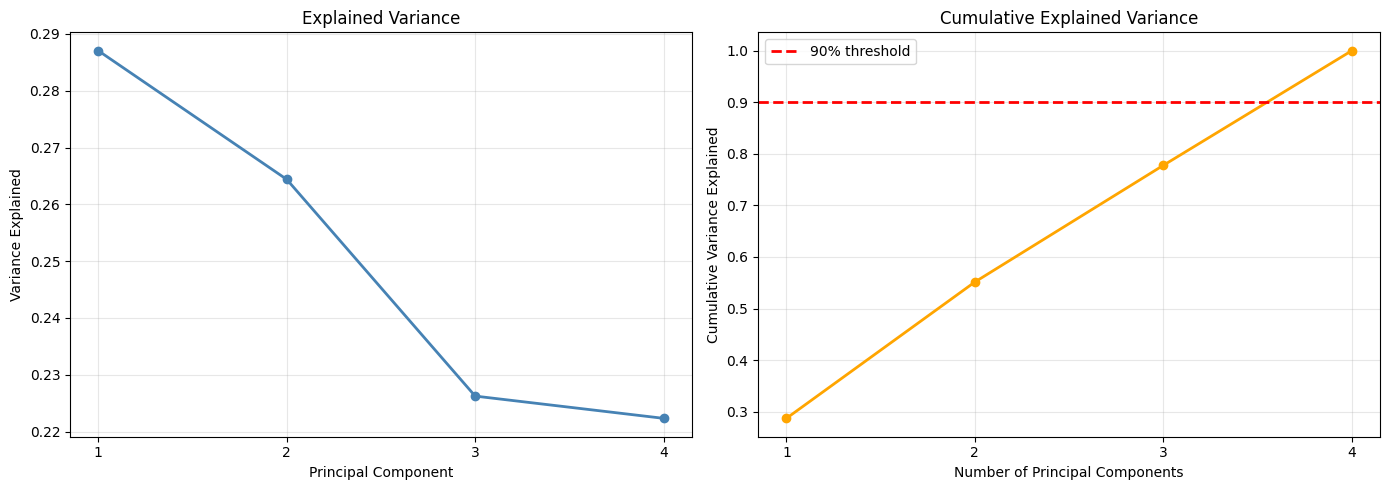

In [159]:
# Scree plot and cumulative variance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
ax1.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', color='steelblue', linewidth=2)
ax1.set_title('Explained Variance')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Variance Explained')
ax1.grid(True, alpha=0.3)
ax1.set_xticks(range(1, len(explained_variance) + 1))

# Cumulative variance
cumulative_variance = np.cumsum(explained_variance)
ax2.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', color='orange', linewidth=2)
ax2.axhline(y=0.9, color='red', linestyle='--', linewidth=2, label='90% threshold')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xlabel('Number of Principal Components')
ax2.set_ylabel('Cumulative Variance Explained')
ax2.set_xticks(range(1, len(cumulative_variance) + 1))
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

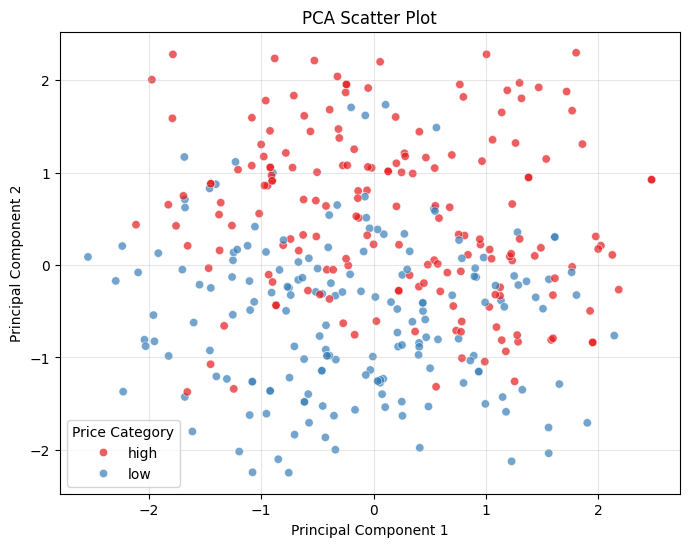

In [160]:
# Scatter plot 2D
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca_transformed[:, 0], y=X_pca_transformed[:, 1], hue=Y, palette='Set1', alpha=0.7)
plt.title('PCA Scatter Plot')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Price Category')
plt.grid(True, alpha=0.3)
plt.show()

In [161]:
# Decide the number of components that explain at least 90% of the variance
n_components = np.argmax(cumulative_variance >= 0.9) + 1
print(f"Number of components explaining at least 90% variance: {n_components}")

Number of components explaining at least 90% variance: 4


## MODEL TRAINING

In [162]:
# Check the shapes of the training and testing sets
print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"\nTrain set class distribution:\n{Y_train.value_counts()}")
print(f"\nTest set class distribution:\n{Y_test.value_counts()}")


Training set shape: (284, 10)
Test set shape: (71, 10)

Train set class distribution:
price_category
high    142
low     142
Name: count, dtype: int64

Test set class distribution:
price_category
high    36
low     35
Name: count, dtype: int64


In [163]:
# Normalize the feature data (important for KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Visualize the first few entries of the scaled training data
X_train_scaled[:3]

array([[ 1.80536821,  1.44669782,  0.67789891,  0.62324134, -0.35634832,
        -0.33071891, -0.47343208, -0.29685452, -0.46785053,  1.93218357],
       [ 1.40063171,  1.44669782, -0.67789891,  1.38338364, -0.35634832,
        -0.33071891, -0.47343208, -0.29685452,  2.13743478, -0.51754917],
       [ 0.69585889, -1.40255448, -0.67789891,  0.17278665,  2.80624304,
        -0.33071891, -0.47343208, -0.29685452, -0.46785053, -0.51754917]])

## K-NEAREST NEIGHBORS

In [164]:
# K-Nearest Neighbors Classifier
knn = KNeighborsClassifier()

# Parametrization for KNN
param_grid = {'n_neighbors': np.arange(1, 21)}
grid_search = GridSearchCV(knn, param_grid, cv=5) # 5-fold cross-validation
grid_search.fit(X_train_scaled, Y_train)

# Visualize the best parameters for KNN
best_k = grid_search.best_params_['n_neighbors']
print(f"Best number of neighbors (k): {best_k}")

Best number of neighbors (k): 10


In [165]:
# Train KNN with the best parameters
knn_best = grid_search.best_estimator_
knn_best.fit(X_train_scaled, Y_train)

# Make predictions on the test set
Y_pred_knn = knn_best.predict(X_test_scaled)

# Evaluate KNN model
knn_accuracy = accuracy_score(Y_test, Y_pred_knn)
print(f"KNN Accuracy: {knn_accuracy:.3f}")
print("\nKNN Confusion Matrix:")
print(confusion_matrix(Y_test, Y_pred_knn))
print("\nKNN Classification Report:")
print(classification_report(Y_test, Y_pred_knn))

KNN Accuracy: 0.775

KNN Confusion Matrix:
[[29  7]
 [ 9 26]]

KNN Classification Report:
              precision    recall  f1-score   support

        high       0.76      0.81      0.78        36
         low       0.79      0.74      0.76        35

    accuracy                           0.77        71
   macro avg       0.78      0.77      0.77        71
weighted avg       0.78      0.77      0.77        71



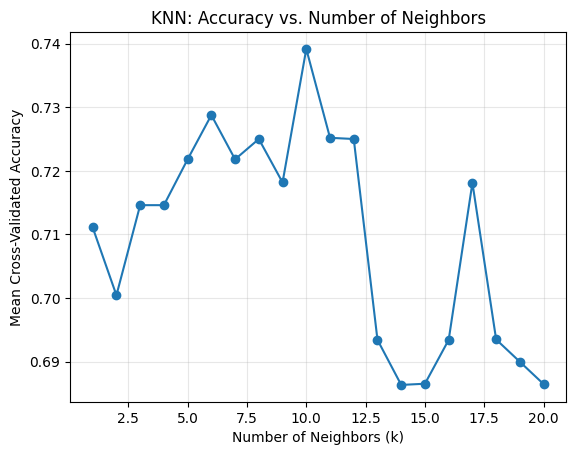

In [166]:
# Plot accuracy vs. number of neighbors
mean_scores = grid_search.cv_results_['mean_test_score']
plt.plot(param_grid['n_neighbors'], mean_scores, marker='o')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Mean Cross-Validated Accuracy')
plt.title('KNN: Accuracy vs. Number of Neighbors')
plt.grid(True, alpha=0.3)
plt.show()

## LOGISTIC REGRESSION

In [167]:
# Logistic Regression Classifier
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Train Logistic Regression model
log_reg.fit(X_train_scaled, Y_train)

# Make predictions on the test set
Y_pred_logreg = log_reg.predict(X_test_scaled)

In [168]:
# Evaluate Logistic Regression model
logreg_accuracy = accuracy_score(Y_test, Y_pred_logreg)
print(f"Logistic Regression Accuracy: {logreg_accuracy:.3f}")
print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(Y_test, Y_pred_logreg))
print("\nLogistic Regression Classification Report:")
print(classification_report(Y_test, Y_pred_logreg))

Logistic Regression Accuracy: 0.831

Logistic Regression Confusion Matrix:
[[28  8]
 [ 4 31]]

Logistic Regression Classification Report:
              precision    recall  f1-score   support

        high       0.88      0.78      0.82        36
         low       0.79      0.89      0.84        35

    accuracy                           0.83        71
   macro avg       0.83      0.83      0.83        71
weighted avg       0.84      0.83      0.83        71



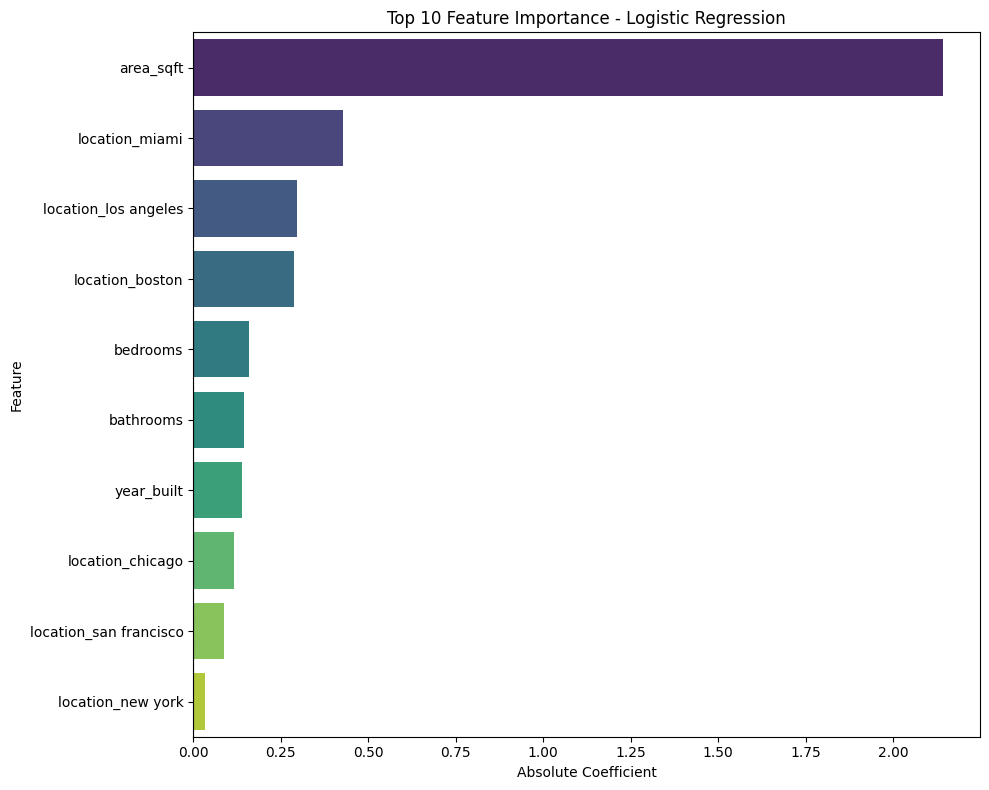

In [169]:
# Feature importance for Logistic Regression
feature_names = X.columns
coefficients = log_reg.coef_[0]
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients,
    'abs_coefficient': np.abs(coefficients)
}).sort_values('abs_coefficient', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=feature_importance.head(10), x='abs_coefficient', y='feature', hue='feature', palette='viridis', legend=False)
plt.title('Top 10 Feature Importance - Logistic Regression')
plt.xlabel('Absolute Coefficient')
plt.ylabel('Feature')
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

## MODEL COMPARISON

In [170]:
# Create comprehensive comparison dataframe
comparison_data = pd.DataFrame({
    'Model': ['KNN', 'Logistic Regression'],
    'Accuracy': [knn_accuracy, logreg_accuracy]
})

print("\n MODEL PERFORMANCE COMPARISON")
print(comparison_data.to_string(index=False))


 MODEL PERFORMANCE COMPARISON
              Model  Accuracy
                KNN  0.774648
Logistic Regression  0.830986


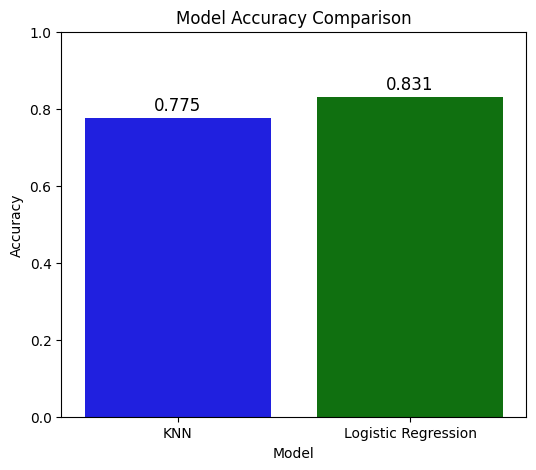

In [171]:
# Plot comparison of model accuracies
plt.figure(figsize=(6, 5))
sns.barplot(data=comparison_data, x='Model', y='Accuracy', hue='Model', palette={'KNN': 'blue', 'Logistic Regression': 'green'}, legend= False)
plt.ylim(0, 1)
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xlabel('Model')
for index, row in comparison_data.iterrows():
    plt.text(index, row.Accuracy + 0.02, f"{row.Accuracy:.3f}", ha='center', fontsize=12)
plt.show()


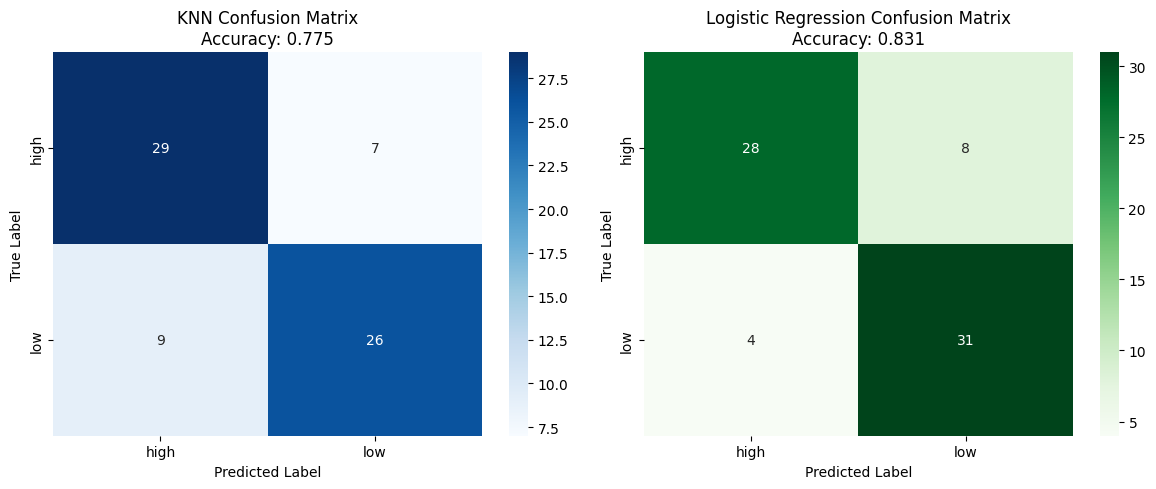

In [172]:
# Define confusion matrices for both models
cm_knn = confusion_matrix(Y_test, Y_pred_knn)
cm_logreg = confusion_matrix(Y_test, Y_pred_logreg)

# Plot the Confusion Matrices Side by Side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['high', 'low'], yticklabels=['high', 'low'], ax=axes[0])
axes[0].set_title(f'KNN Confusion Matrix\nAccuracy: {knn_accuracy:.3f}')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(cm_logreg, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['high', 'low'], yticklabels=['high', 'low'], ax=axes[1])
axes[1].set_title(f'Logistic Regression Confusion Matrix\nAccuracy: {logreg_accuracy:.3f}')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

## CROSS VALIDATION

In [173]:
# Pipelines for KNN and Logistic Regression
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=best_k))
])

pipe_logreg = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000, random_state=42))
])

# Cross-Validation for KNN
cv_scores_knn = cross_val_score(pipe_knn, X_train, Y_train, cv=5)

# Cross-Validation for Logistic Regression
cv_scores_logreg = cross_val_score(pipe_logreg, X_train, Y_train, cv=5)

print(f"KNN CV Scores: {cv_scores_knn}")
print(f"KNN Mean CV Score: {cv_scores_knn.mean():.3f}")
print(f"\nLogistic Regression CV Scores: {cv_scores_logreg}")
print(f"Logistic Regression Mean CV Score: {cv_scores_logreg.mean():.3f}")

KNN CV Scores: [0.68421053 0.8245614  0.70175439 0.80701754 0.66071429]
KNN Mean CV Score: 0.736

Logistic Regression CV Scores: [0.70175439 0.85964912 0.84210526 0.85964912 0.75      ]
Logistic Regression Mean CV Score: 0.803


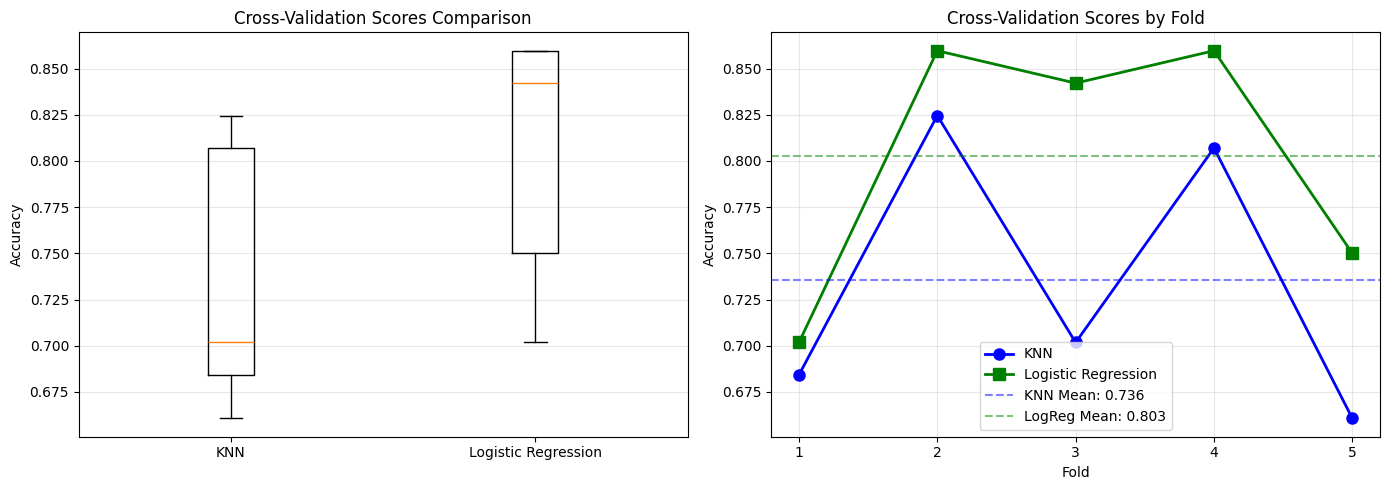

In [174]:
# Visualize Cross-Validation Scores
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot comparison
ax1.boxplot([cv_scores_knn, cv_scores_logreg], tick_labels=['KNN', 'Logistic Regression'])
ax1.set_title('Cross-Validation Scores Comparison')
ax1.set_ylabel('Accuracy')
ax1.grid(True, axis='y', alpha=0.3)

# Individual fold scores
folds = np.arange(1, 6)
ax2.plot(folds, cv_scores_knn, color='blue', marker='o', label='KNN', linewidth=2, markersize=8)
ax2.plot(folds, cv_scores_logreg, color='green', marker='s', label='Logistic Regression', linewidth=2, markersize=8)
ax2.axhline(cv_scores_knn.mean(), color='blue', linestyle='--', alpha=0.5, label=f'KNN Mean: {cv_scores_knn.mean():.3f}')
ax2.axhline(cv_scores_logreg.mean(), color='green', linestyle='--', alpha=0.5, label=f'LogReg Mean: {cv_scores_logreg.mean():.3f}')
ax2.set_xlabel('Fold')
ax2.set_ylabel('Accuracy')
ax2.set_title('Cross-Validation Scores by Fold')
ax2.legend(loc='lower center')
ax2.grid(True, alpha=0.3)
ax2.set_xticks(folds)

plt.tight_layout()
plt.show()

## FINAL SUMMARY

In [175]:
print("FINAL MODEL COMPARISON SUMMARY")
print(f"\nKNN (k={best_k}):")
print(f"  - Test Accuracy: {knn_accuracy:.3f}")
print(f"  - CV Mean Score: {cv_scores_knn.mean():.3f}")
print(f"\nLogistic Regression:")
print(f"  - Test Accuracy: {logreg_accuracy:.3f}")
print(f"  - CV Mean Score: {cv_scores_logreg.mean():.3f}")

if logreg_accuracy > knn_accuracy:
    print(f"\n Best Model: Logistic Regression (Accuracy: {logreg_accuracy:.3f})")
else:
    print(f"\n Best Model: KNN with k={best_k} (Accuracy: {knn_accuracy:.3f})")

FINAL MODEL COMPARISON SUMMARY

KNN (k=10):
  - Test Accuracy: 0.775
  - CV Mean Score: 0.736

Logistic Regression:
  - Test Accuracy: 0.831
  - CV Mean Score: 0.803

 Best Model: Logistic Regression (Accuracy: 0.831)
